<a href="https://colab.research.google.com/github/FadhilTaufiqurrachman/PCVK_Ganjil_2026-2027_FadhilTaufiqurrachman/blob/main/Week9PCVK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Pertemuan 9 - Morfologi

NIM : 244107020090

Nama : Fadhil Taufiqurrachman

Kelas : TI 3G

No Absen : 06

Mata Kuliah : Pengolahan Citra Dan Visi Komputer

In [ ]:
# Inisialisasi Identitas Mahasiswa
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Fadhil Taufiqurrachman'
NIM = '244107020090'

waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))

print('NAMA   :', NAMA)
print('NIM    :', NIM)
print('WAKTU  :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())
kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN  :', hashlib.sha256(kunci.encode()).hexdigest()[:16])

NAMA   : Fadhil Taufiqurrachman
NIM    : 244107020090
WAKTU  : 2026-10-26 10:58:57 WIB
SISTEM : 3.13.16 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN  : 35cc5f27f2379abe


D. Praktikum Morfologi

1. Menyambungkan Ke Google Drive Dan Inisialisasi Folder Image

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
BASE_PATH = '/content/drive/MyDrive/Education/Current Semester College File /PCVK Image/'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


2. Import Library Yang Akan Digunakan

In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

3. Membuat Fungsi Dilasi Manual

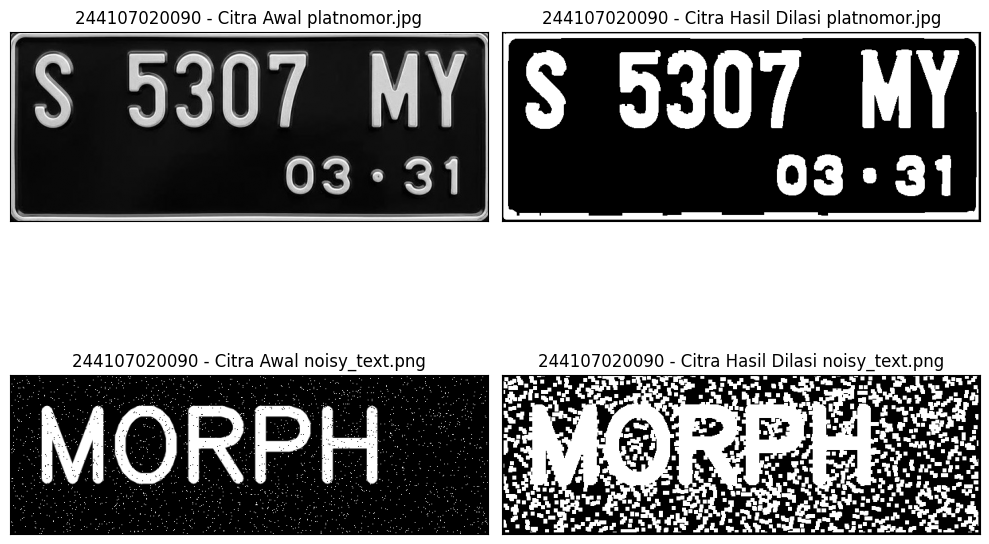

In [ ]:
# Fungsi Dilasi Tanpa Library
def dilasi_citra(F, w):
    # Size Image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate Structure Element Dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

img_gray_plat = cv2.imread(BASE_PATH + 'platnomor.jpg', 0)
img_gray_noisy = cv2.imread(BASE_PATH + 'noisy_text.png', 0)

ret_plat, img_binary_plat = cv2.threshold(img_gray_plat, 125, 200, cv2.THRESH_BINARY)
ret_noisy, img_binary_noisy = cv2.threshold(img_gray_noisy, 125, 200, cv2.THRESH_BINARY)
w = 5

# Memanggil Fungsi Dilasi Untuk Kedua Matriks Citra Biner
imgD_plat = dilasi_citra(img_binary_plat, w)
imgD_noisy = dilasi_citra(img_binary_noisy, w)

plt.figure(figsize=(10, 8))

plt.subplot(221), plt.imshow(img_gray_plat, cmap='gray')
plt.title('244107020090 - Citra Awal platnomor.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(imgD_plat, cmap='gray')
plt.title('244107020090 - Citra Hasil Dilasi platnomor.jpg'), plt.xticks([]), plt.yticks([])

plt.subplot(223), plt.imshow(img_gray_noisy, cmap='gray')
plt.title('244107020090 - Citra Awal noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(imgD_noisy, cmap='gray')
plt.title('244107020090 - Citra Hasil Dilasi noisy_text.png'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

4. Membuat Program Dilasi Structuring Element Dilasi (SED) Dengan Library OpenCV

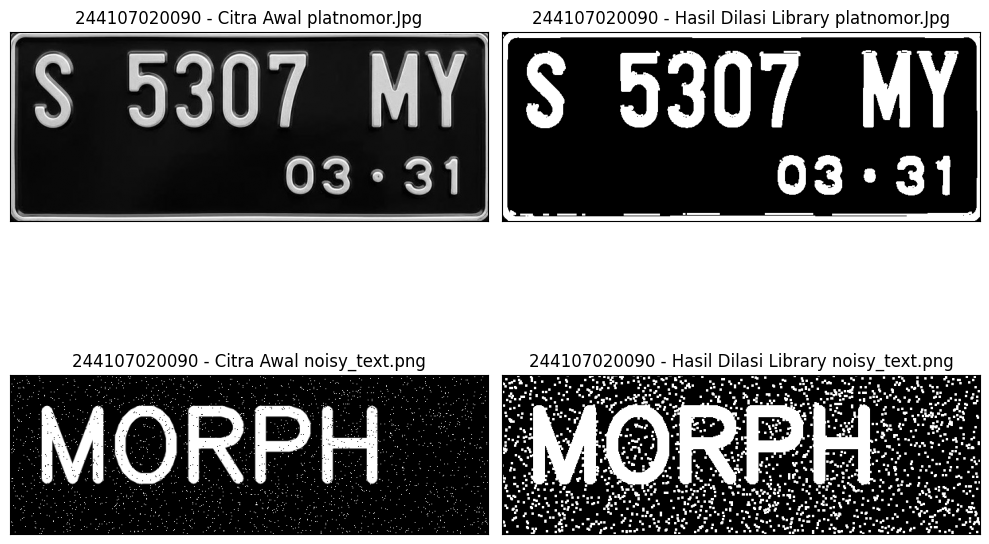

In [ ]:
img_gray_plat = cv2.imread(BASE_PATH + 'platnomor.jpg', 0)
img_gray_noisy = cv2.imread(BASE_PATH + 'noisy_text.png', 0)

ret_plat, img_binary_plat = cv2.threshold(img_gray_plat, 127, 255, cv2.THRESH_BINARY)
ret_noisy, img_binary_noisy = cv2.threshold(img_gray_noisy, 127, 255, cv2.THRESH_BINARY)

kernel = np.ones((3, 3), np.uint8)

dilasi_plat = cv2.dilate(img_binary_plat, kernel, iterations=1)
dilasi_noisy = cv2.dilate(img_binary_noisy, kernel, iterations=1)

plt.figure(figsize=(10, 8))

plt.subplot(221), plt.imshow(img_gray_plat, cmap='gray')
plt.title('244107020090 - Citra Awal platnomor.Jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(dilasi_plat, cmap='gray')
plt.title('244107020090 - Hasil Dilasi Library platnomor.Jpg'), plt.xticks([]), plt.yticks([])

plt.subplot(223), plt.imshow(img_gray_noisy, cmap='gray')
plt.title('244107020090 - Citra Awal noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(dilasi_noisy, cmap='gray')
plt.title('244107020090 - Hasil Dilasi Library noisy_text.png'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

5. Membuat Fungsi Dilasi Manual

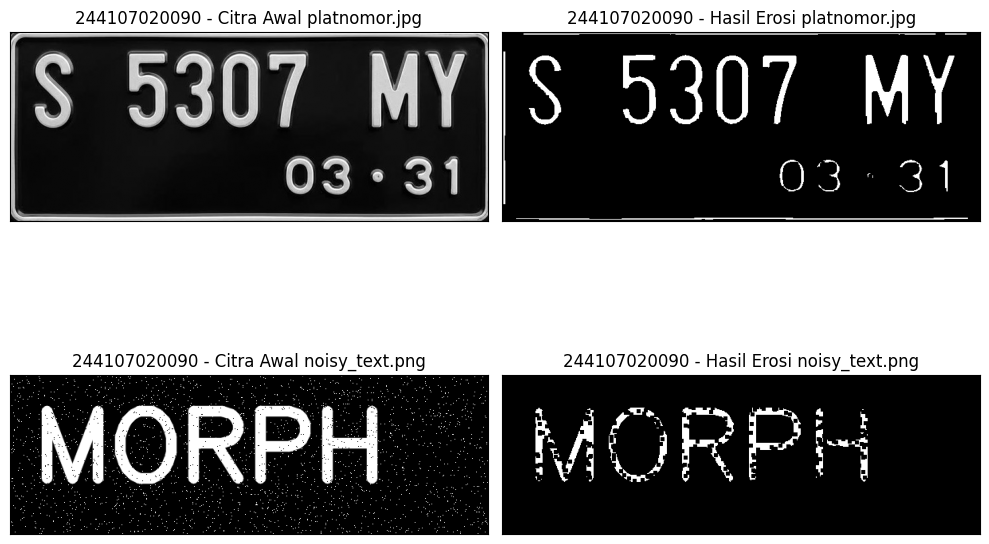

In [ ]:
# Fungsi Erosi Tanpa Library
def erosi_citra(F, k):
    # Size Image
    m, n = F.shape

    # Membuat Structure Element Erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant : i + constant + 1, j - constant : j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

img_gray_plat = cv2.imread(BASE_PATH + 'platnomor.jpg', 0)
img_gray_noisy = cv2.imread(BASE_PATH + 'noisy_text.png', 0)

ret_plat, img_binary_plat = cv2.threshold(img_gray_plat, 175, 255, cv2.THRESH_BINARY)
ret_noisy, img_binary_noisy = cv2.threshold(img_gray_noisy, 175, 255, cv2.THRESH_BINARY)

k = 5

imgE_plat = erosi_citra(img_binary_plat, k)
imgE_noisy = erosi_citra(img_binary_noisy, k)

plt.figure(figsize=(10, 8))

plt.subplot(221), plt.imshow(img_gray_plat, cmap='gray')
plt.title('244107020090 - Citra Awal platnomor.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(imgE_plat, cmap='gray')
plt.title('244107020090 - Hasil Erosi platnomor.jpg'), plt.xticks([]), plt.yticks([])

plt.subplot(223), plt.imshow(img_gray_noisy, cmap='gray')
plt.title('244107020090 - Citra Awal noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(imgE_noisy, cmap='gray')
plt.title('244107020090 - Hasil Erosi noisy_text.png'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

6. Membuat Program Erosi Structuring Element Erosi (SE) Dengan Library OpenCV

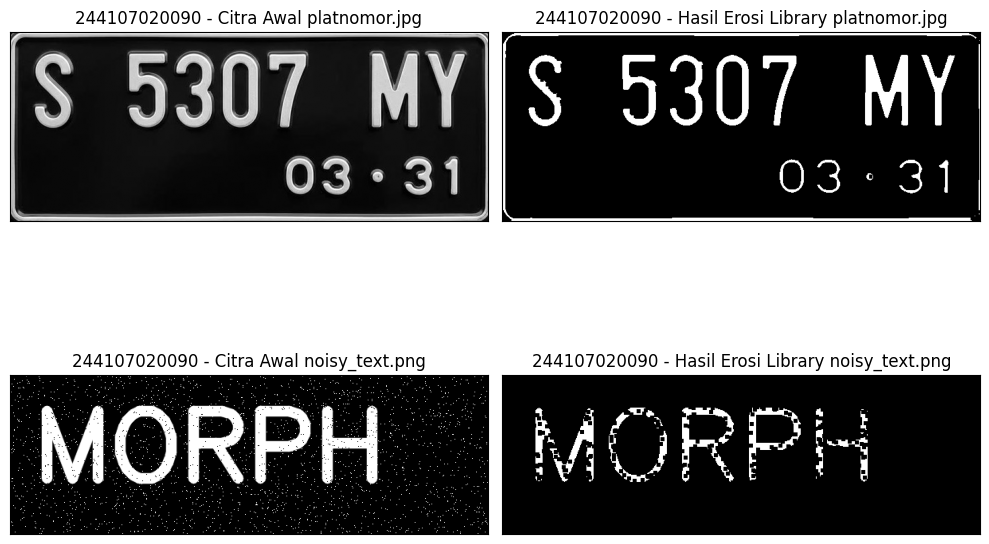

In [ ]:
img_gray_plat = cv2.imread(BASE_PATH + 'platnomor.jpg', 0)
img_gray_noisy = cv2.imread(BASE_PATH + 'noisy_text.png', 0)

ret_plat, img_binary_plat = cv2.threshold(img_gray_plat, 127, 255, cv2.THRESH_BINARY)
ret_noisy, img_binary_noisy = cv2.threshold(img_gray_noisy, 127, 255, cv2.THRESH_BINARY)

kernel = np.ones((5, 5), np.uint8)

erosion_plat = cv2.erode(img_binary_plat, kernel, iterations=1)
erosion_noisy = cv2.erode(img_binary_noisy, kernel, iterations=1)

plt.figure(figsize=(10, 8))

plt.subplot(221), plt.imshow(img_gray_plat, cmap='gray')
plt.title('244107020090 - Citra Awal platnomor.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(erosion_plat, cmap='gray')
plt.title('244107020090 - Hasil Erosi Library platnomor.jpg'), plt.xticks([]), plt.yticks([])

plt.subplot(223), plt.imshow(img_gray_noisy, cmap='gray')
plt.title('244107020090 - Citra Awal noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(erosion_noisy, cmap='gray')
plt.title('244107020090 - Hasil Erosi Library noisy_text.png'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

7. Membuat Program Operasi Opening

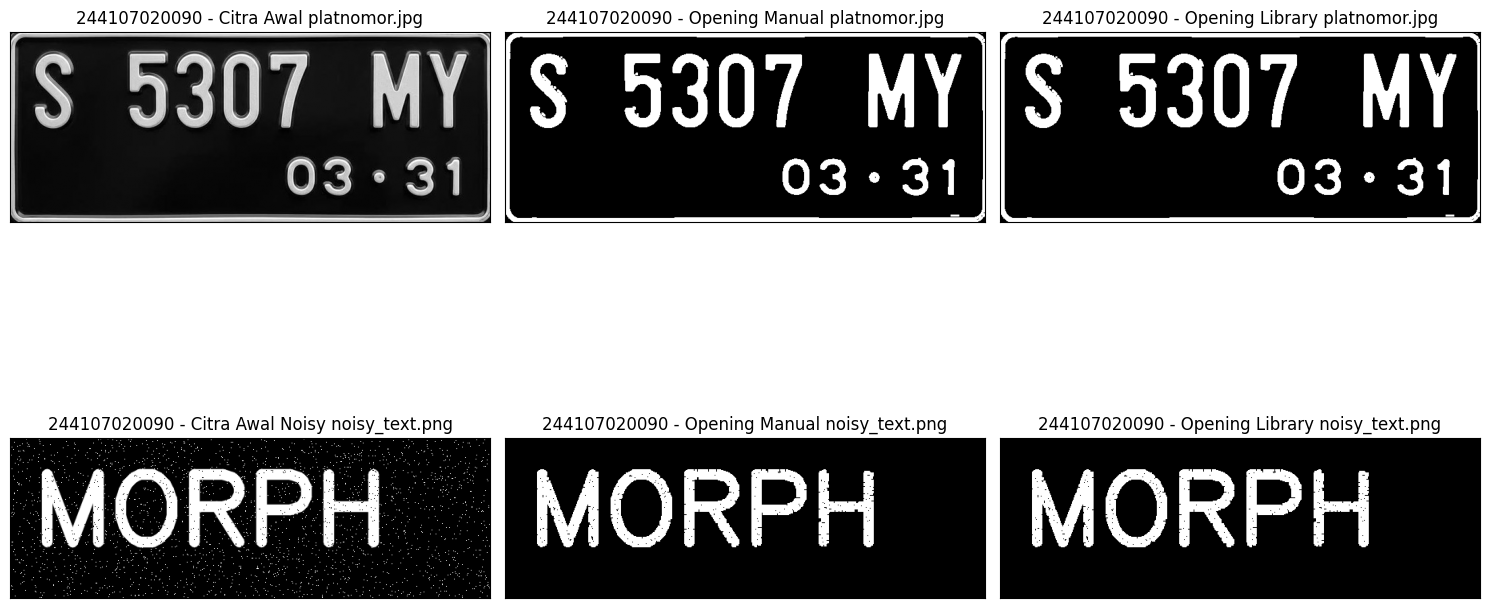

In [ ]:
# Membuat Fungsi Erosi Manual
def erosi_citra(citra, k):
    m, n = citra.shape
    pad = k // 2
    hasil = np.zeros((m, n), dtype=np.uint8)
    # Menambahkan Padding Pada Citra
    pad_citra = np.pad(citra, pad, mode='constant', constant_values=255)
    # Melakukan Perulangan Untuk Operasi Erosi
    for i in range(m):
        for j in range(n):
            hasil[i, j] = np.min(pad_citra[i:i+k, j:j+k])
    return hasil

# Membuat Fungsi Dilasi Manual
def dilasi_citra(citra, k):
    m, n = citra.shape
    pad = k // 2
    hasil = np.zeros((m, n), dtype=np.uint8)
    # Menambahkan Padding Pada Citra
    pad_citra = np.pad(citra, pad, mode='constant', constant_values=0)
    # Melakukan Perulangan Untuk Operasi Dilasi
    for i in range(m):
        for j in range(n):
            hasil[i, j] = np.max(pad_citra[i:i+k, j:j+k])
    return hasil

# Mendefinisikan Ukuran Kernel Dan Structuring Element
k = 3
kernel = np.ones((3,3), np.uint8)

# Memproses Gambar Plat Nomor
# Membaca Citra Plat Nomor Dan Melakukan Thresholding
img_plat = cv2.imread(BASE_PATH + 'platnomor.jpg', 0)
ret_plat, thresh_plat = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
# Melakukan Operasi Opening Manual Dan Library
open_manual_plat = dilasi_citra(erosi_citra(thresh_plat, k), k)
open_lib_plat = cv2.morphologyEx(thresh_plat, cv2.MORPH_OPEN, kernel)

# Memproses Gambar Noisy Text
# Membaca Citra Noisy Text Dan Melakukan Thresholding
img_noisy = cv2.imread(BASE_PATH + 'noisy_text.png', 0)
ret_noisy, thresh_noisy = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)
# Melakukan Operasi Opening Manual Dan Library
open_manual_noisy = dilasi_citra(erosi_citra(thresh_noisy, k), k)
open_lib_noisy = cv2.morphologyEx(thresh_noisy, cv2.MORPH_OPEN, kernel)

# Menampilkan Seluruh Hasil Dalam Satu Figure
plt.figure(figsize=(15, 10))

# Menampilkan Hasil Plat Nomor
plt.subplot(231), plt.imshow(img_plat, cmap='gray')
plt.title('244107020090 - Citra Awal platnomor.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(232), plt.imshow(open_manual_plat, cmap='gray')
plt.title('244107020090 - Opening Manual platnomor.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(233), plt.imshow(open_lib_plat, cmap='gray')
plt.title('244107020090 - Opening Library platnomor.jpg'), plt.xticks([]), plt.yticks([])

# Menampilkan Hasil Noisy Text
plt.subplot(234), plt.imshow(img_noisy, cmap='gray')
plt.title('244107020090 - Citra Awal Noisy noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(235), plt.imshow(open_manual_noisy, cmap='gray')
plt.title('244107020090 - Opening Manual noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(236), plt.imshow(open_lib_noisy, cmap='gray')
plt.title('244107020090 - Opening Library noisy_text.png'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

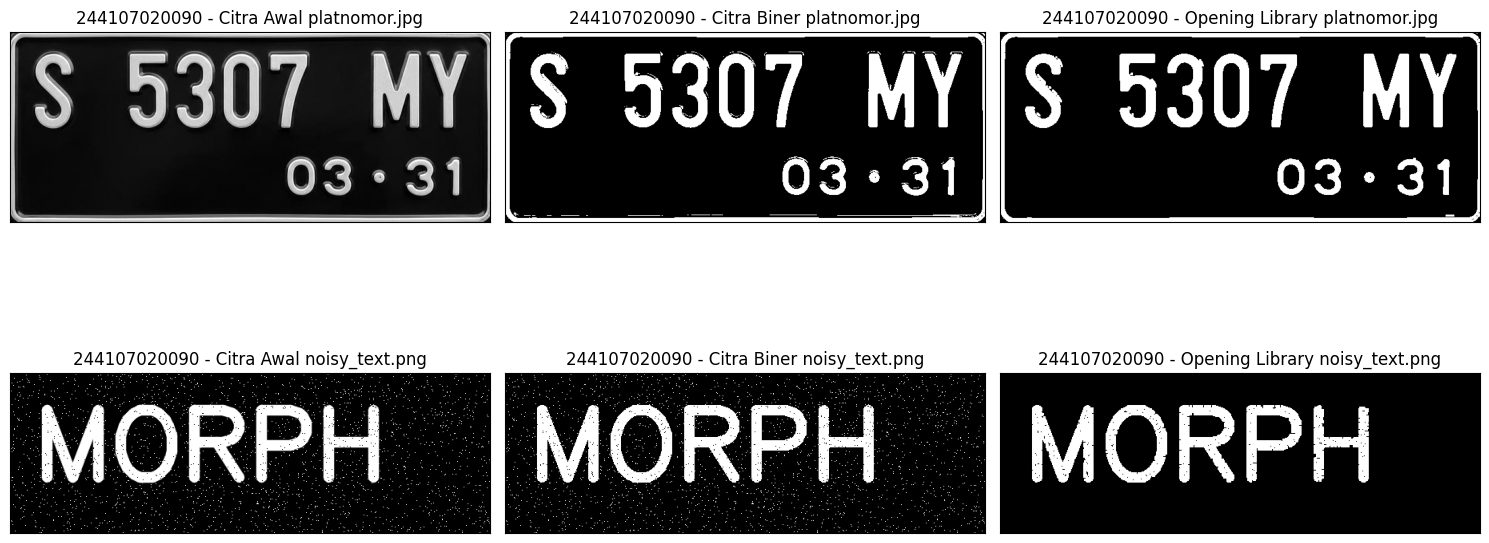

In [ ]:
# Membaca Citra Plat Nomor Dan Citra Noisy Text
img_plat = cv2.imread(BASE_PATH + 'platnomor.jpg', 0)
img_noisy = cv2.imread(BASE_PATH + 'noisy_text.png', 0)

# Melakukan Thresholding Pada Kedua Citra
ret_plat, thresh_plat = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
ret_noisy, thresh_noisy = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)

# Membuat Structuring Element (Kernel) Berbentuk Square 3x3
kernel = np.ones((3,3), np.uint8)

# Melakukan Operasi Opening Menggunakan Library Morphology OpenCV
open_lib_plat = cv2.morphologyEx(thresh_plat, cv2.MORPH_OPEN, kernel)
open_lib_noisy = cv2.morphologyEx(thresh_noisy, cv2.MORPH_OPEN, kernel)

# Menampilkan Hasil Citra Dalam Satu Figure
plt.figure(figsize=(15, 8))

# Menampilkan Hasil Plat Nomor
plt.subplot(231), plt.imshow(img_plat, cmap='gray')
plt.title('244107020090 - Citra Awal platnomor.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(232), plt.imshow(thresh_plat, cmap='gray')
plt.title('244107020090 - Citra Biner platnomor.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(233), plt.imshow(open_lib_plat, cmap='gray')
plt.title('244107020090 - Opening Library platnomor.jpg'), plt.xticks([]), plt.yticks([])

# Menampilkan Hasil Noisy Text
plt.subplot(234), plt.imshow(img_noisy, cmap='gray')
plt.title('244107020090 - Citra Awal noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(235), plt.imshow(thresh_noisy, cmap='gray')
plt.title('244107020090 - Citra Biner noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(236), plt.imshow(open_lib_noisy, cmap='gray')
plt.title('244107020090 - Opening Library noisy_text.png'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

8. Membuat Program Operasi Closing

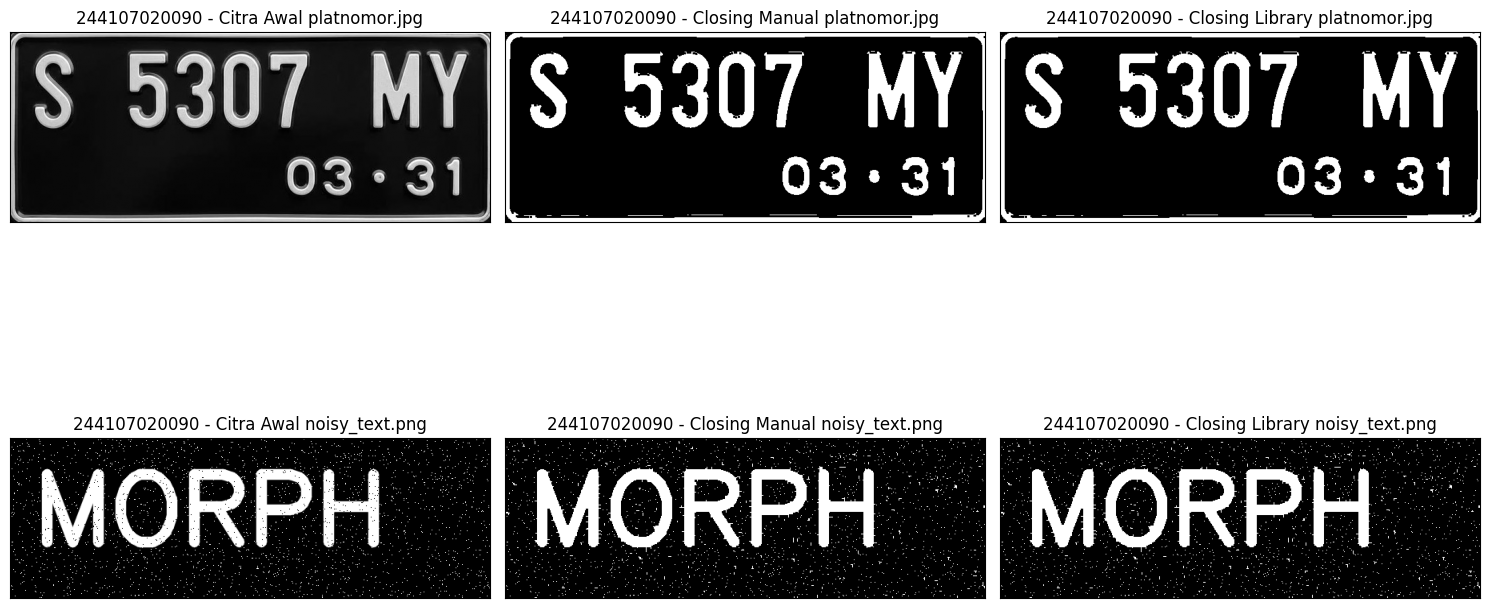

In [ ]:
# Membuat Fungsi Erosi Manual
def erosi_citra(citra, k):
    m, n = citra.shape
    pad = k // 2
    hasil = np.zeros((m, n), dtype=np.uint8)
    # Menambahkan Padding Pada Citra
    pad_citra = np.pad(citra, pad, mode='constant', constant_values=255)
    # Melakukan Perulangan Untuk Operasi Erosi
    for i in range(m):
        for j in range(n):
            hasil[i, j] = np.min(pad_citra[i:i+k, j:j+k])
    return hasil

# Membuat Fungsi Dilasi Manual
def dilasi_citra(citra, k):
    m, n = citra.shape
    pad = k // 2
    hasil = np.zeros((m, n), dtype=np.uint8)
    # Menambahkan Padding Pada Citra
    pad_citra = np.pad(citra, pad, mode='constant', constant_values=0)
    # Melakukan Perulangan Untuk Operasi Dilasi
    for i in range(m):
        for j in range(n):
            hasil[i, j] = np.max(pad_citra[i:i+k, j:j+k])
    return hasil

# Membaca Citra Plat Nomor Dan Citra Noisy Text
img_plat = cv2.imread(BASE_PATH + 'platnomor.jpg', 0)
img_noisy = cv2.imread(BASE_PATH + 'noisy_text.png', 0)

# Melakukan Thresholding Pada Kedua Citra
ret_plat, thresh_plat = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
ret_noisy, thresh_noisy = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)

# Mendefinisikan Ukuran Kernel Dan Structuring Element 3x3 Sesuai Soal
k = 3
kernel = np.ones((3,3), np.uint8)

# Melakukan Operasi Closing Manual (Dilasi Dilanjutkan Erosi)
close_manual_plat = erosi_citra(dilasi_citra(thresh_plat, k), k)
close_manual_noisy = erosi_citra(dilasi_citra(thresh_noisy, k), k)

# Melakukan Operasi Closing Menggunakan Library Morphology OpenCV
close_lib_plat = cv2.morphologyEx(thresh_plat, cv2.MORPH_CLOSE, kernel)
close_lib_noisy = cv2.morphologyEx(thresh_noisy, cv2.MORPH_CLOSE, kernel)

# Menampilkan Hasil Citra Dalam Satu Figure
plt.figure(figsize=(15, 10))

# Menampilkan Hasil Plat Nomor
plt.subplot(231), plt.imshow(img_plat, cmap='gray')
plt.title('244107020090 - Citra Awal platnomor.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(232), plt.imshow(close_manual_plat, cmap='gray')
plt.title('244107020090 - Closing Manual platnomor.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(233), plt.imshow(close_lib_plat, cmap='gray')
plt.title('244107020090 - Closing Library platnomor.jpg'), plt.xticks([]), plt.yticks([])

# Menampilkan Hasil Noisy Text
plt.subplot(234), plt.imshow(img_noisy, cmap='gray')
plt.title('244107020090 - Citra Awal noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(235), plt.imshow(close_manual_noisy, cmap='gray')
plt.title('244107020090 - Closing Manual noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(236), plt.imshow(close_lib_noisy, cmap='gray')
plt.title('244107020090 - Closing Library noisy_text.png'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

9. Membuat Program Dilasi Structuring Element Berbentuk
Cross 3 x 3 dan 5 x 5

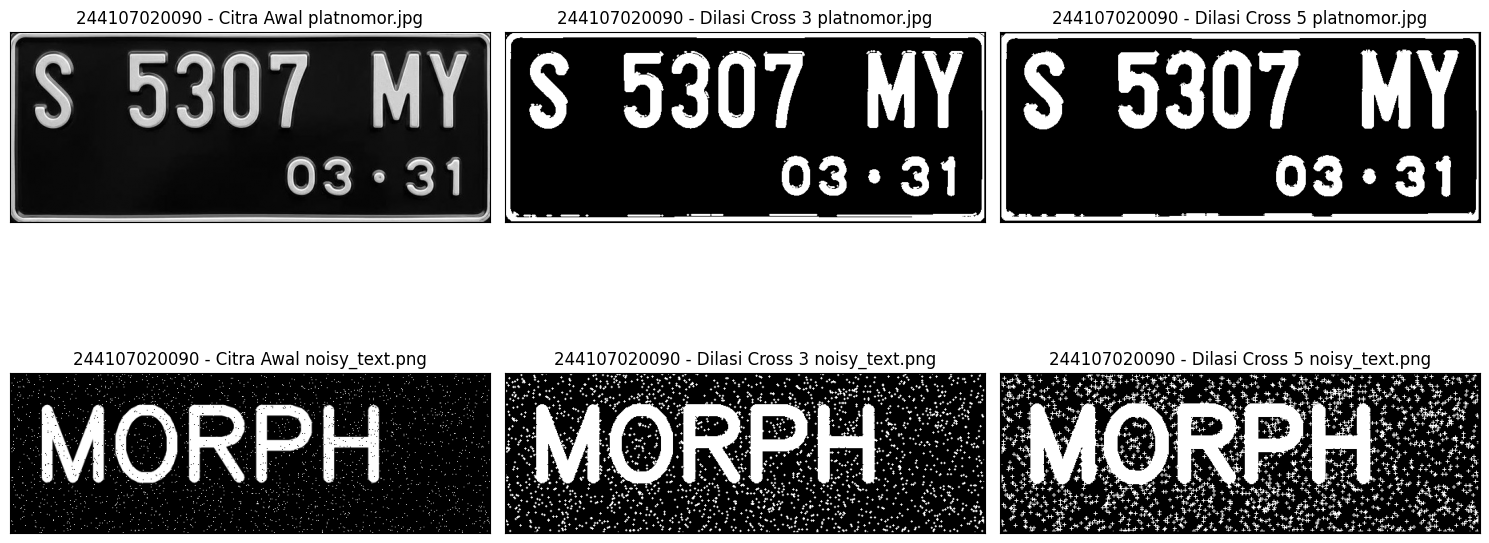

In [ ]:
# Membaca Citra Plat Nomor Dan Noisy Text
img_plat = cv2.imread(BASE_PATH + 'platnomor.jpg', 0)
img_noisy = cv2.imread(BASE_PATH + 'noisy_text.png', 0)

# Melakukan Thresholding Pada Kedua Citra
ret_plat, thresh_plat = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
ret_noisy, thresh_noisy = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)

# Membuat Fungsi Dilasi Manual Dengan Parameter SED
def dilasi_citra_cross(F, SED):
    # Mendapatkan Ukuran Citra
    p, q = F.shape
    # Membuat Array Kosong Untuk Citra Hasil
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Mendapatkan Dimensi SED Dan Nilai Konstanta
    w = SED.shape[0]
    constant1 = (w - 1) // 2

    # Melakukan Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

# Membuat Generate Structure Element Dilasi (SED) Cross 3x3
sed_cross_3 = np.array([[0, 1, 0],
                        [1, 1, 1],
                        [0, 1, 0]], dtype=np.uint8)

# Membuat Generate Structure Element Dilasi (SED) Cross 5x5
sed_cross_5 = np.array([[0, 0, 1, 0, 0],
                        [0, 0, 1, 0, 0],
                        [1, 1, 1, 1, 1],
                        [0, 0, 1, 0, 0],
                        [0, 0, 1, 0, 0]], dtype=np.uint8)

# Menerapkan Operasi Dilasi Pada Citra Plat Nomor
dilasi_plat_3 = dilasi_citra_cross(thresh_plat, sed_cross_3)
dilasi_plat_5 = dilasi_citra_cross(thresh_plat, sed_cross_5)

# Menerapkan Operasi Dilasi Pada Citra Noisy Text
dilasi_noisy_3 = dilasi_citra_cross(thresh_noisy, sed_cross_3)
dilasi_noisy_5 = dilasi_citra_cross(thresh_noisy, sed_cross_5)

# Menampilkan Seluruh Hasil Citra Ke Dalam Figure
plt.figure(figsize=(15, 8))

# Menampilkan Hasil Untuk Plat Nomor
plt.subplot(231), plt.imshow(img_plat, cmap='gray')
plt.title('244107020090 - Citra Awal platnomor.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(232), plt.imshow(dilasi_plat_3, cmap='gray')
plt.title('244107020090 - Dilasi Cross 3 platnomor.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(233), plt.imshow(dilasi_plat_5, cmap='gray')
plt.title('244107020090 - Dilasi Cross 5 platnomor.jpg'), plt.xticks([]), plt.yticks([])

# Menampilkan Hasil Untuk Noisy Text
plt.subplot(234), plt.imshow(img_noisy, cmap='gray')
plt.title('244107020090 - Citra Awal noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(235), plt.imshow(dilasi_noisy_3, cmap='gray')
plt.title('244107020090 - Dilasi Cross 3 noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(236), plt.imshow(dilasi_noisy_5, cmap='gray')
plt.title('244107020090 - Dilasi Cross 5 noisy_text.png'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

10. Membuat Program Dilasi Structuring Element Berbentuk
Circular 3 x 3 dan 5 x 5

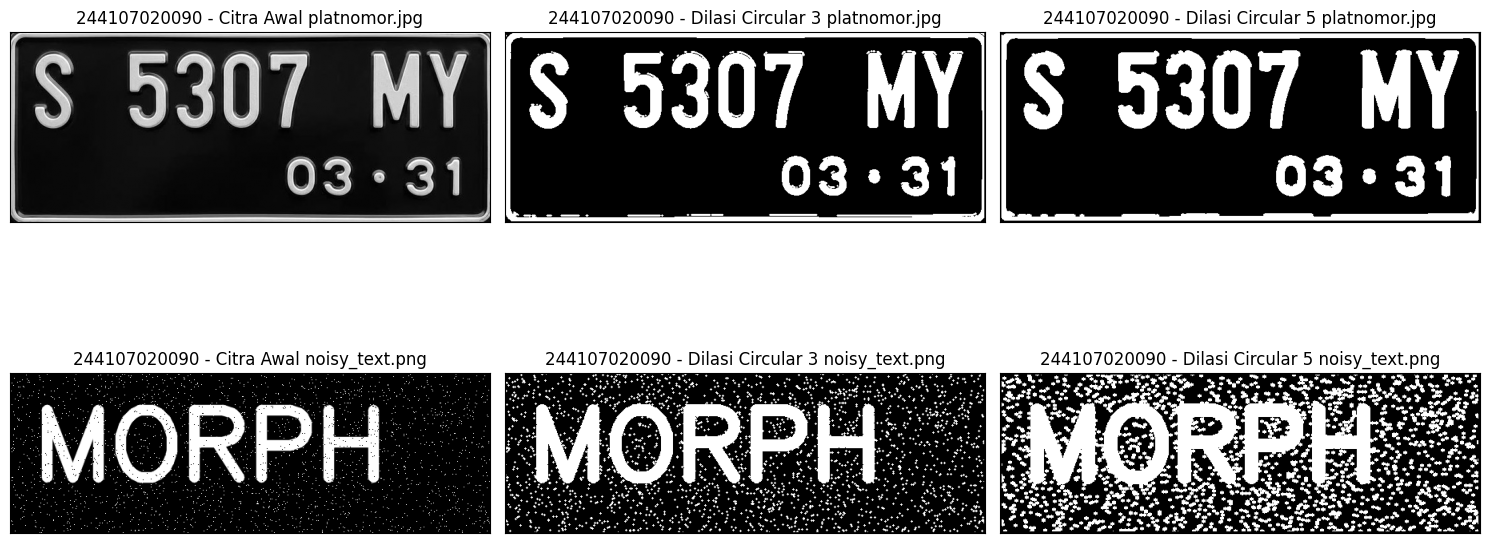

In [ ]:
# Membaca Citra Plat Nomor Dan Citra Noisy Text
img_plat = cv2.imread(BASE_PATH + 'platnomor.jpg', 0)
img_noisy = cv2.imread(BASE_PATH + 'noisy_text.png', 0)

# Melakukan Thresholding Pada Kedua Citra
ret_plat, thresh_plat = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
ret_noisy, thresh_noisy = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)

# Membuat Fungsi Dilasi Manual Dengan Parameter Ukuran Window (w)
def dilasi_citra_circular(F, w):
    # Mendapatkan Ukuran Citra
    p, q = F.shape
    # Membuat Array Kosong Untuk Citra Hasil
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate Structure Element Dilasi (SED) Berbentuk Circular / Ellipse
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2

    # Melakukan Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

# Menerapkan Operasi Dilasi Circular Pada Citra Plat Nomor (Ukuran 3 Dan 5)
dilasi_plat_circ3 = dilasi_citra_circular(thresh_plat, 3)
dilasi_plat_circ5 = dilasi_citra_circular(thresh_plat, 5)

# Menerapkan Operasi Dilasi Circular Pada Citra Noisy Text (Ukuran 3 Dan 5)
dilasi_noisy_circ3 = dilasi_citra_circular(thresh_noisy, 3)
dilasi_noisy_circ5 = dilasi_citra_circular(thresh_noisy, 5)

# Menampilkan Seluruh Hasil Citra Ke Dalam Figure
plt.figure(figsize=(15, 8))

# Menampilkan Hasil Untuk Plat Nomor
plt.subplot(231), plt.imshow(img_plat, cmap='gray')
plt.title('244107020090 - Citra Awal platnomor.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(232), plt.imshow(dilasi_plat_circ3, cmap='gray')
plt.title('244107020090 - Dilasi Circular 3 platnomor.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(233), plt.imshow(dilasi_plat_circ5, cmap='gray')
plt.title('244107020090 - Dilasi Circular 5 platnomor.jpg'), plt.xticks([]), plt.yticks([])

# Menampilkan Hasil Untuk Noisy Text
plt.subplot(234), plt.imshow(img_noisy, cmap='gray')
plt.title('244107020090 - Citra Awal noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(235), plt.imshow(dilasi_noisy_circ3, cmap='gray')
plt.title('244107020090 - Dilasi Circular 3 noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(236), plt.imshow(dilasi_noisy_circ5, cmap='gray')
plt.title('244107020090 - Dilasi Circular 5 noisy_text.png'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

11. Membuat Program Erosi Structuring Element Berbentuk
Rectangle 3 x 3 dan 5 x 5

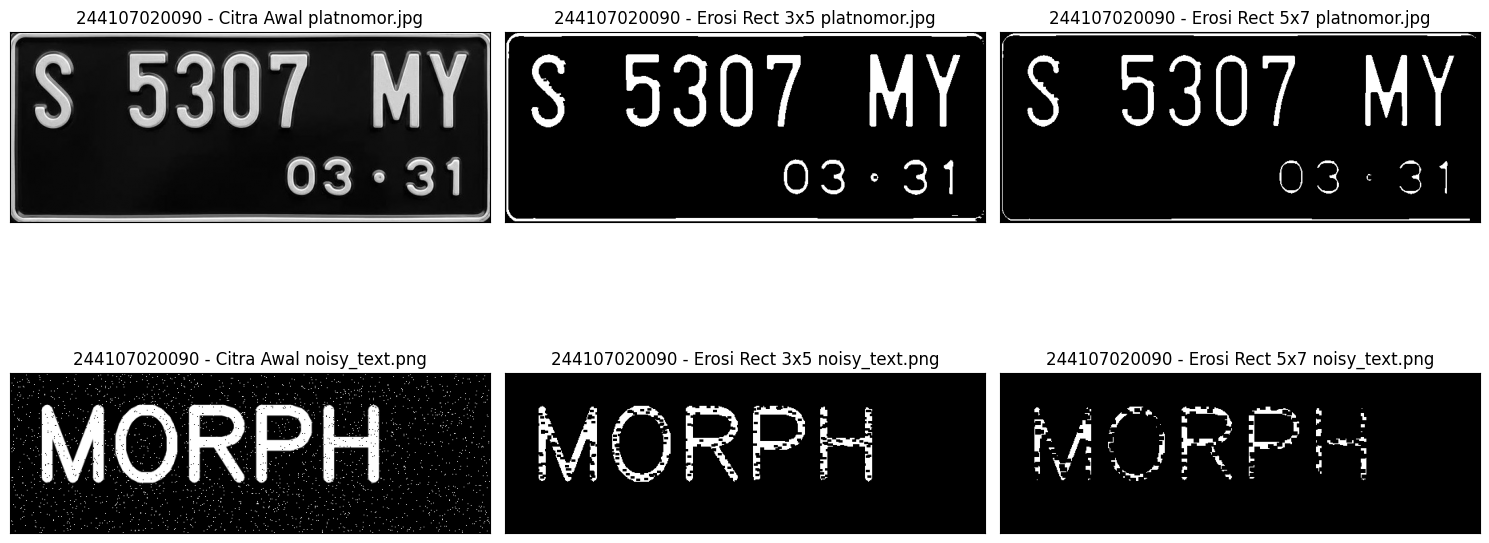

In [ ]:
# Membaca Citra Plat Nomor Dan Citra Noisy Text
img_plat = cv2.imread(BASE_PATH + 'platnomor.jpg', 0)
img_noisy = cv2.imread(BASE_PATH + 'noisy_text.png', 0)

# Melakukan Thresholding Pada Kedua Citra
ret_plat, thresh_plat = cv2.threshold(img_plat, 127, 255, cv2.THRESH_BINARY)
ret_noisy, thresh_noisy = cv2.threshold(img_noisy, 127, 255, cv2.THRESH_BINARY)

# Membuat Fungsi Erosi Manual Dengan Parameter Rectangle p (Lebar) Dan l (Tinggi)
def erosi_citra_rect(F, p, l):
    # Mendapatkan Ukuran Image
    m, n = F.shape

    # Generate Structure Element Erosi (SE) Persegi Panjang
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))

    # Menentukan Nilai Konstanta Sesuai Dimensi SE
    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2

    # Membuat Array Kosong Untuk Citra Hasil
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Melakukan Proses Erosi Manual
    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i - constant1 : i + constant1 + 1, j - constant2 : j + constant2 + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

# Menerapkan Operasi Erosi Rectangle Pada Citra Plat Nomor
# Ukuran 3x5 (p=5, l=3) Dan Ukuran 5x7 (p=7, l=5)
erosi_plat_3x5 = erosi_citra_rect(thresh_plat, 5, 3)
erosi_plat_5x7 = erosi_citra_rect(thresh_plat, 7, 5)

# Menerapkan Operasi Erosi Rectangle Pada Citra Noisy Text
erosi_noisy_3x5 = erosi_citra_rect(thresh_noisy, 5, 3)
erosi_noisy_5x7 = erosi_citra_rect(thresh_noisy, 7, 5)

# Menampilkan Seluruh Hasil Citra Ke Dalam Figure
plt.figure(figsize=(15, 8))

# Menampilkan Hasil Untuk Plat Nomor
plt.subplot(231), plt.imshow(img_plat, cmap='gray')
plt.title('244107020090 - Citra Awal platnomor.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(232), plt.imshow(erosi_plat_3x5, cmap='gray')
plt.title('244107020090 - Erosi Rect 3x5 platnomor.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(233), plt.imshow(erosi_plat_5x7, cmap='gray')
plt.title('244107020090 - Erosi Rect 5x7 platnomor.jpg'), plt.xticks([]), plt.yticks([])

# Menampilkan Hasil Untuk Noisy Text
plt.subplot(234), plt.imshow(img_noisy, cmap='gray')
plt.title('244107020090 - Citra Awal noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(235), plt.imshow(erosi_noisy_3x5, cmap='gray')
plt.title('244107020090 - Erosi Rect 3x5 noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(236), plt.imshow(erosi_noisy_5x7, cmap='gray')
plt.title('244107020090 - Erosi Rect 5x7 noisy_text.png'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

12. Membuat Program Erosi Structuring Element Berbentuk
Vertical 3 x 3 dan 5 x 5

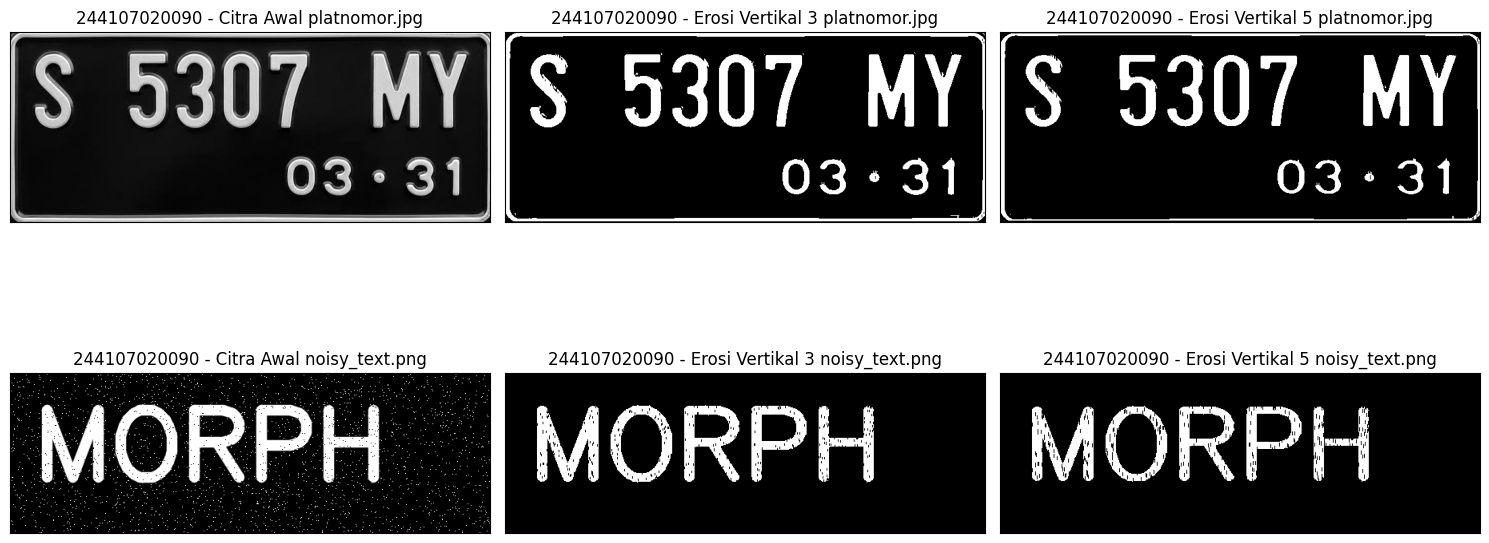

In [ ]:
# Membaca Citra Plat Nomor Dan Citra Noisy Text
img_plat = cv2.imread(BASE_PATH + 'platnomor.jpg', 0)
img_noisy = cv2.imread(BASE_PATH + 'noisy_text.png', 0)

# Melakukan Thresholding Pada Kedua Citra
ret_plat, thresh_plat = cv2.threshold(img_plat, 127, 255, cv2.THRESH_BINARY)
ret_noisy, thresh_noisy = cv2.threshold(img_noisy, 127, 255, cv2.THRESH_BINARY)

# Membuat Fungsi Erosi Manual Line Vertikal
def erosi_citra_vertikal(F, k):
    # Mendapatkan Ukuran Citra
    m, n = F.shape

    # Generate Structure Element Erosi (SE) Line Vertikal (Lebar 1, Tinggi k)
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))

    # Menentukan Nilai Konstanta Untuk Baris (Tinggi)
    constant = (k - 1) // 2

    # Membuat Array Kosong Untuk Citra Hasil
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Melakukan Proses Erosi
    for i in range(constant, m - constant):
        # Karena Lebar Kernel Hanya 1, Perulangan Kolom Menggunakan Seluruh Lebar n
        for j in range(n):
            # Memotong Area Gambar Sesuai Ukuran SE Vertikal
            temp = F[i - constant : i + constant + 1, j : j + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

# Menerapkan Operasi Erosi Line Vertikal Pada Citra Plat Nomor
erosi_plat_v3 = erosi_citra_vertikal(thresh_plat, 3)
erosi_plat_v5 = erosi_citra_vertikal(thresh_plat, 5)

# Menerapkan Operasi Erosi Line Vertikal Pada Citra Noisy Text
erosi_noisy_v3 = erosi_citra_vertikal(thresh_noisy, 3)
erosi_noisy_v5 = erosi_citra_vertikal(thresh_noisy, 5)

# Menampilkan Seluruh Hasil Citra Ke Dalam Figure
plt.figure(figsize=(15, 8))

# Menampilkan Hasil Untuk Plat Nomor
plt.subplot(231), plt.imshow(img_plat, cmap='gray')
plt.title('244107020090 - Citra Awal platnomor.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(232), plt.imshow(erosi_plat_v3, cmap='gray')
plt.title('244107020090 - Erosi Vertikal 3 platnomor.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(233), plt.imshow(erosi_plat_v5, cmap='gray')
plt.title('244107020090 - Erosi Vertikal 5 platnomor.jpg'), plt.xticks([]), plt.yticks([])

# Menampilkan Hasil Untuk Noisy Text
plt.subplot(234), plt.imshow(img_noisy, cmap='gray')
plt.title('244107020090 - Citra Awal noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(235), plt.imshow(erosi_noisy_v3, cmap='gray')
plt.title('244107020090 - Erosi Vertikal 3 noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(236), plt.imshow(erosi_noisy_v5, cmap='gray')
plt.title('244107020090 - Erosi Vertikal 5 noisy_text.png'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

13. Membuat Program Transformasi Top-Hat Structuring Element 3 X 3

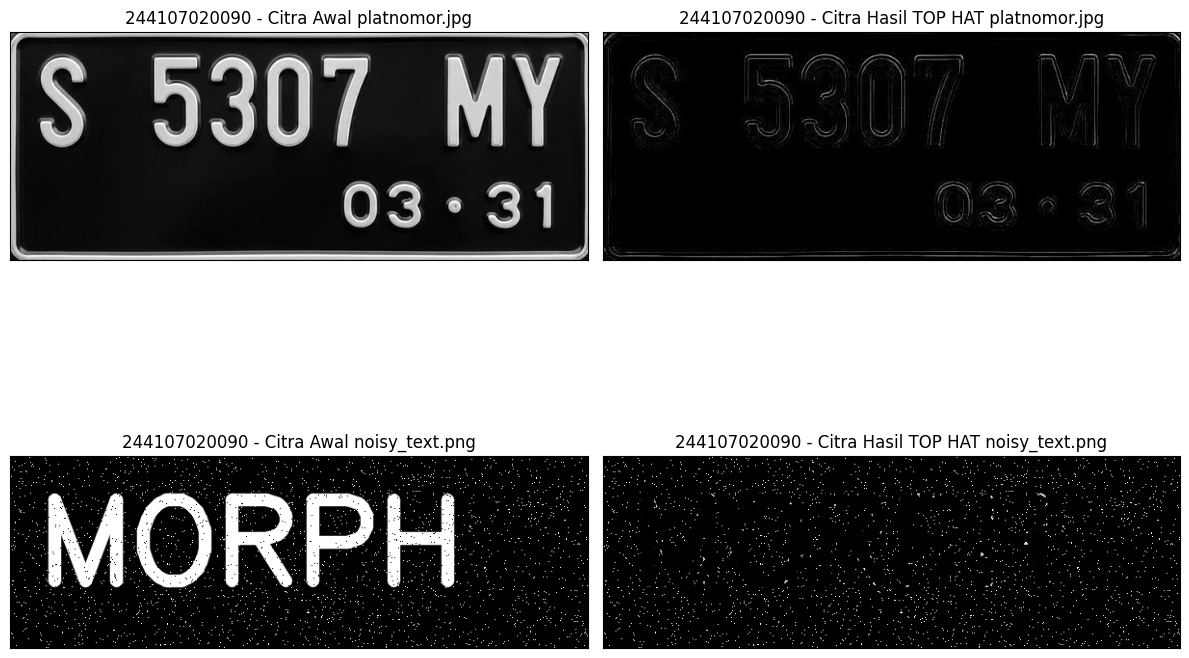

In [ ]:
# Membaca Citra Plat Nomor Dan Citra Noisy Text Dalam Format Grayscale
img_plat = cv2.imread(BASE_PATH + 'platnomor.jpg', 0)
img_noisy = cv2.imread(BASE_PATH + 'noisy_text.png', 0)

# Mendapatkan Kernel Structuring Element 3x3 Sesuai Instruksi Soal
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Mengaplikasikan Operasi Top-Hat Pada Kedua Citra Menggunakan Library
tophat_plat = cv2.morphologyEx(img_plat, cv2.MORPH_TOPHAT, kernel)
tophat_noisy = cv2.morphologyEx(img_noisy, cv2.MORPH_TOPHAT, kernel)

# Menampilkan Seluruh Hasil Citra Ke Dalam Figure Secara Berdampingan
plt.figure(figsize=(12, 10))

# Menampilkan Hasil Untuk Plat Nomor
plt.subplot(221), plt.imshow(img_plat, cmap='gray')
plt.title('244107020090 - Citra Awal platnomor.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(tophat_plat, cmap='gray')
plt.title('244107020090 - Citra Hasil TOP HAT platnomor.jpg'), plt.xticks([]), plt.yticks([])

# Menampilkan Hasil Untuk Noisy Text
plt.subplot(223), plt.imshow(img_noisy, cmap='gray')
plt.title('244107020090 - Citra Awal noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(tophat_noisy, cmap='gray')
plt.title('244107020090 - Citra Hasil TOP HAT noisy_text.png'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

14. Membuat Program Transformasi Black-Hat Structuring Element 3 X 3

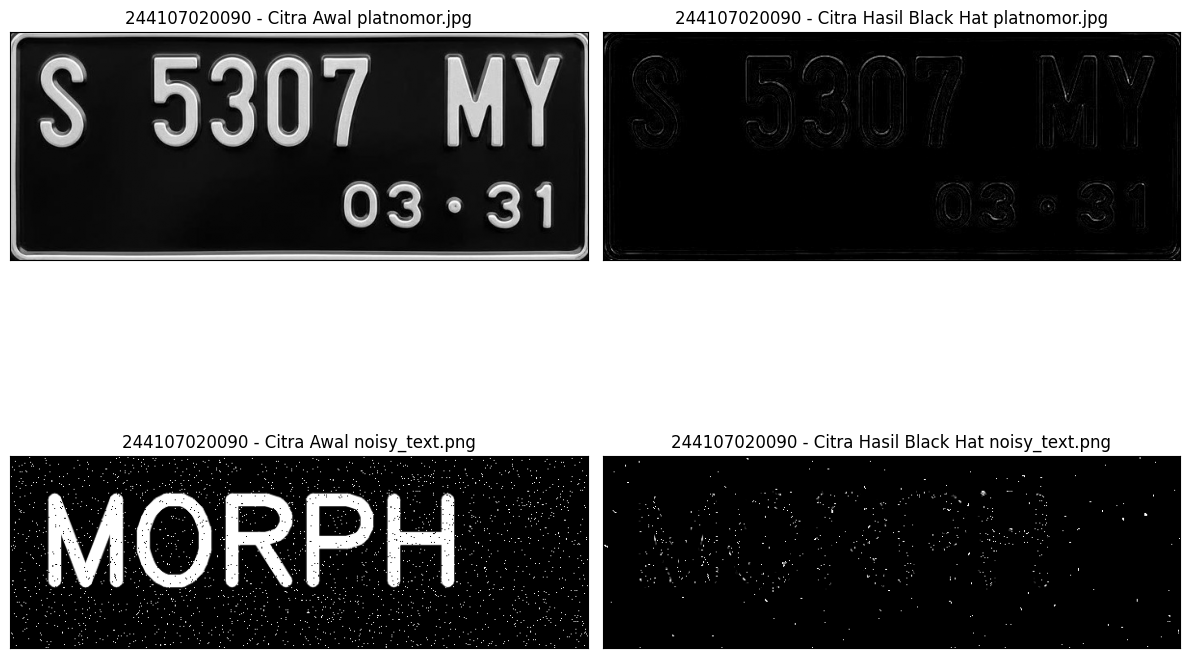

In [ ]:
# Membaca Citra Plat Nomor Dan Citra Noisy Text Dalam Format Grayscale
img_plat = cv2.imread(BASE_PATH + 'platnomor.jpg', 0)
img_noisy = cv2.imread(BASE_PATH + 'noisy_text.png', 0)

# Mendapatkan Kernel Structuring Element 3x3 Sesuai Instruksi
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Mengaplikasikan Operasi Black-Hat Pada Kedua Citra Menggunakan Library
blackhat_plat = cv2.morphologyEx(img_plat, cv2.MORPH_BLACKHAT, kernel)
blackhat_noisy = cv2.morphologyEx(img_noisy, cv2.MORPH_BLACKHAT, kernel)

# Menampilkan Seluruh Hasil Citra Ke Dalam Figure Secara Berdampingan
plt.figure(figsize=(12, 10))

# Menampilkan Hasil Untuk Plat Nomor
plt.subplot(221), plt.imshow(img_plat, cmap='gray')
plt.title('244107020090 - Citra Awal platnomor.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(blackhat_plat, cmap='gray')
plt.title('244107020090 - Citra Hasil Black Hat platnomor.jpg'), plt.xticks([]), plt.yticks([])

# Menampilkan Hasil Untuk Noisy Text
plt.subplot(223), plt.imshow(img_noisy, cmap='gray')
plt.title('244107020090 - Citra Awal noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(blackhat_noisy, cmap='gray')
plt.title('244107020090 - Citra Hasil Black Hat noisy_text.png'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

15. Membuat Program Skeleton

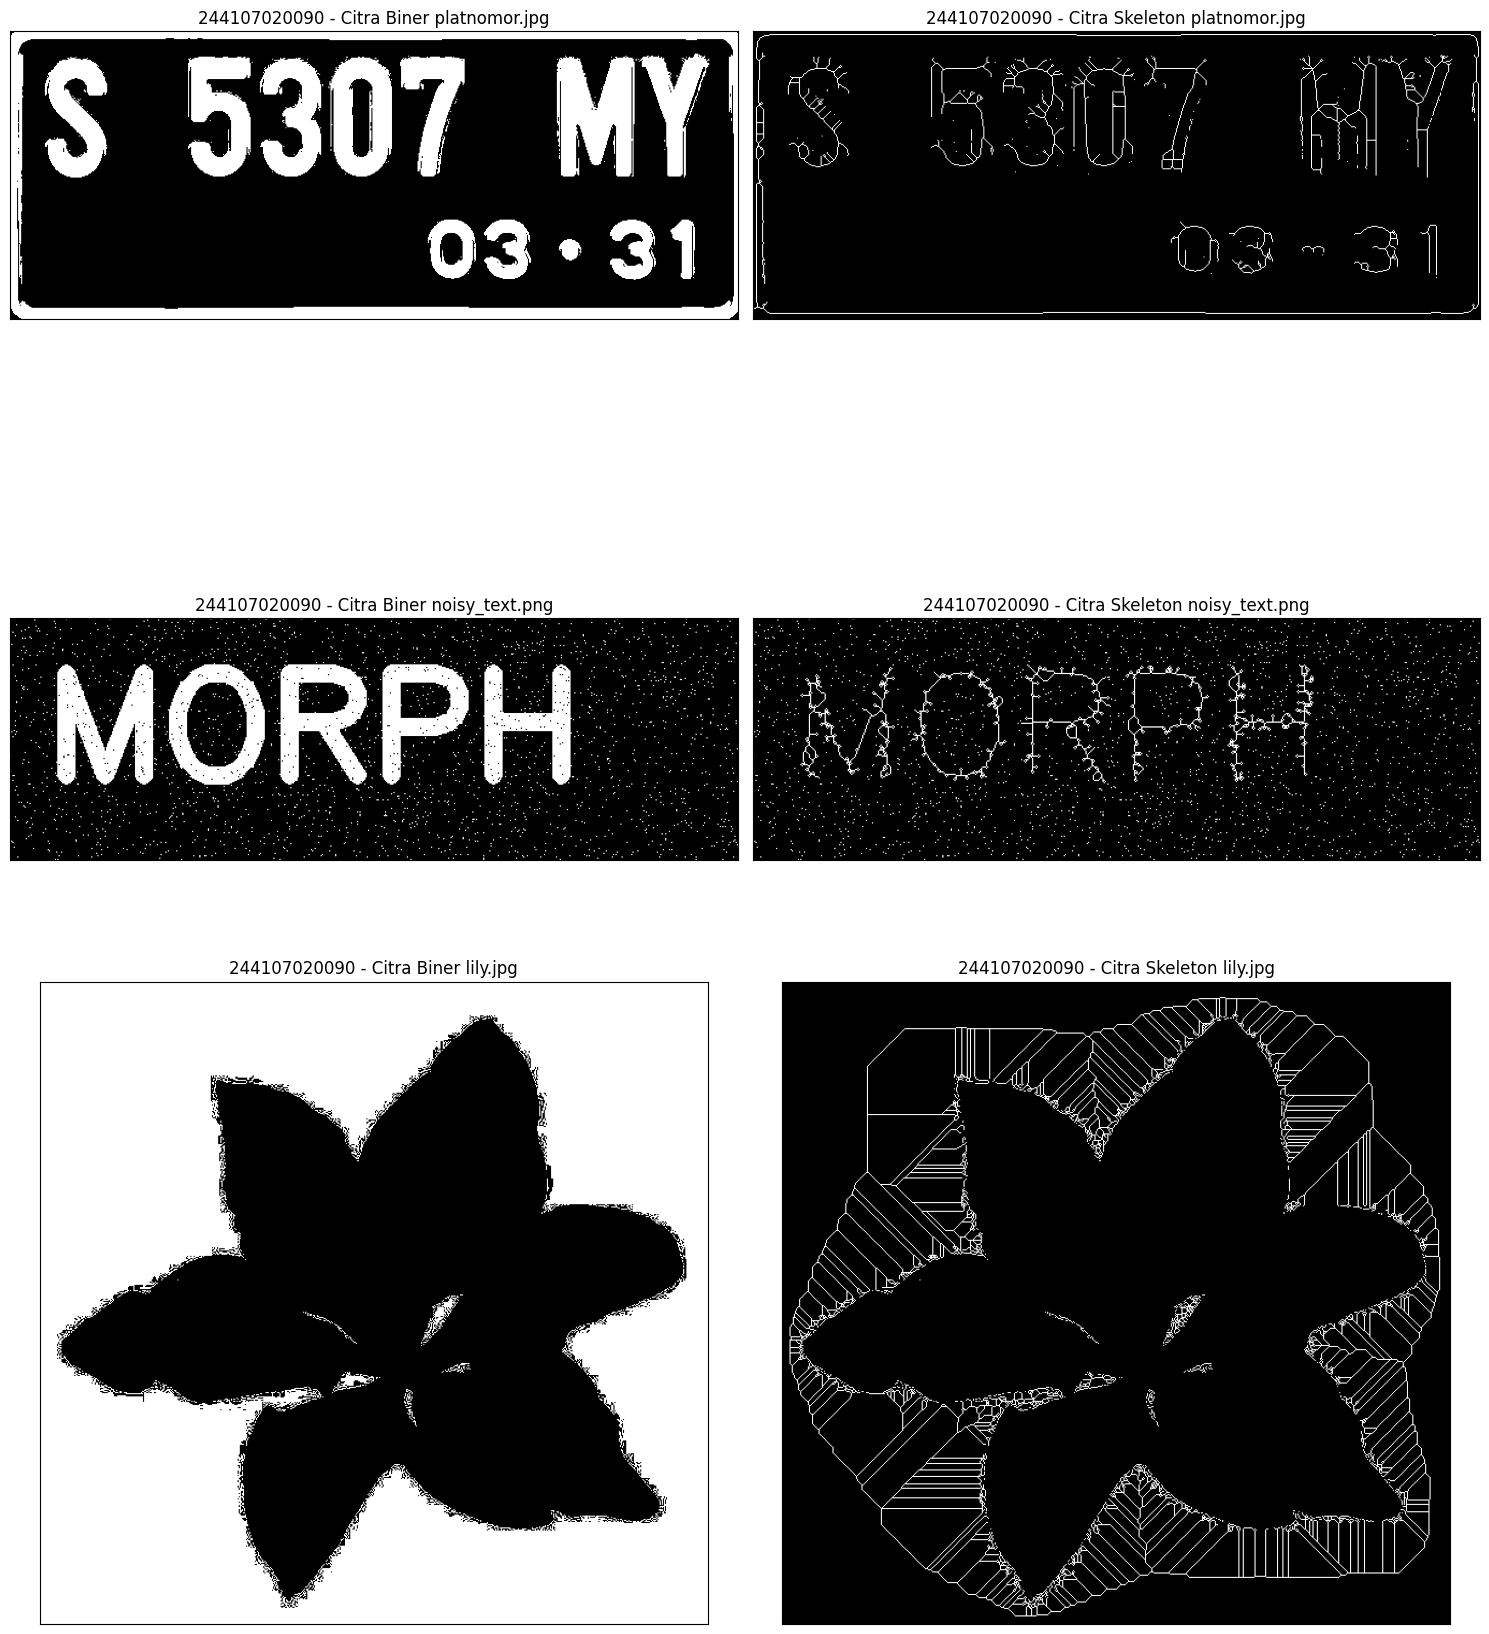

In [ ]:
# Mengimpor Library Ekstra Yang Dibutuhkan Untuk Skeletonize
from skimage import filters
from skimage.morphology import skeletonize

# Membaca Citra Plat Nomor, Noisy Text, Dan Bunga Lily
img_plat = cv2.imread(BASE_PATH + 'platnomor.jpg', 0)
img_noisy = cv2.imread(BASE_PATH + 'noisy_text.png', 0)
img_lily = cv2.imread(BASE_PATH + 'lily.jpg', 0)

# === Proses Untuk Plat Nomor ===
# Melakukan Thresholding Triangle Pada Citra Plat Nomor
binary_plat = img_plat > filters.threshold_triangle(img_plat)
# Mengubah Nilai Boolean Menjadi Biner Angka (1 Dan 0) Pada Plat Nomor
binary_cp_plat = binary_plat.copy()
binary_cp_plat[binary_cp_plat == True] = 1
binary_cp_plat[binary_cp_plat == False] = 0
# Mengeksekusi Fungsi Skeletonize Pada Citra Plat Nomor
skeleton_plat = skeletonize(binary_cp_plat)

# === Proses Untuk Noisy Text ===
# Melakukan Thresholding Triangle Pada Citra Noisy Text
binary_noisy = img_noisy > filters.threshold_triangle(img_noisy)
# Mengubah Nilai Boolean Menjadi Biner Angka (1 Dan 0) Pada Noisy Text
binary_cp_noisy = binary_noisy.copy()
binary_cp_noisy[binary_cp_noisy == True] = 1
binary_cp_noisy[binary_cp_noisy == False] = 0
# Mengeksekusi Fungsi Skeletonize Pada Citra Noisy Text
skeleton_noisy = skeletonize(binary_cp_noisy)

# === Proses Untuk Bunga Lily ===
# Melakukan Thresholding Triangle Pada Citra Bunga Lily
binary_lily = img_lily > filters.threshold_triangle(img_lily)
# Mengubah Nilai Boolean Menjadi Biner Angka (1 Dan 0) Pada Bunga Lily
binary_cp_lily = binary_lily.copy()
binary_cp_lily[binary_cp_lily == True] = 1
binary_cp_lily[binary_cp_lily == False] = 0
# Mengeksekusi Fungsi Skeletonize Pada Citra Bunga Lily
skeleton_lily = skeletonize(binary_cp_lily)

# Menampilkan Citra Biner Dan Hasil Skeleton Secara Berdampingan
# Menggunakan Grid 3x2 Untuk Mengakomodasi 3 Gambar
plt.figure(figsize=(15, 18))

# Menampilkan Hasil Untuk Plat Nomor
plt.subplot(321), plt.imshow(binary_cp_plat, cmap='gray')
plt.title('244107020090 - Citra Biner platnomor.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(322), plt.imshow(skeleton_plat, cmap='gray')
plt.title('244107020090 - Citra Skeleton platnomor.jpg'), plt.xticks([]), plt.yticks([])

# Menampilkan Hasil Untuk Noisy Text
plt.subplot(323), plt.imshow(binary_cp_noisy, cmap='gray')
plt.title('244107020090 - Citra Biner noisy_text.png'), plt.xticks([]), plt.yticks([])
plt.subplot(324), plt.imshow(skeleton_noisy, cmap='gray')
plt.title('244107020090 - Citra Skeleton noisy_text.png'), plt.xticks([]), plt.yticks([])

# Menampilkan Hasil Untuk Bunga Lily
plt.subplot(325), plt.imshow(binary_cp_lily, cmap='gray')
plt.title('244107020090 - Citra Biner lily.jpg'), plt.xticks([]), plt.yticks([])
plt.subplot(326), plt.imshow(skeleton_lily, cmap='gray')
plt.title('244107020090 - Citra Skeleton lily.jpg'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

16. Membuat Program Skeleton Citra Inversi

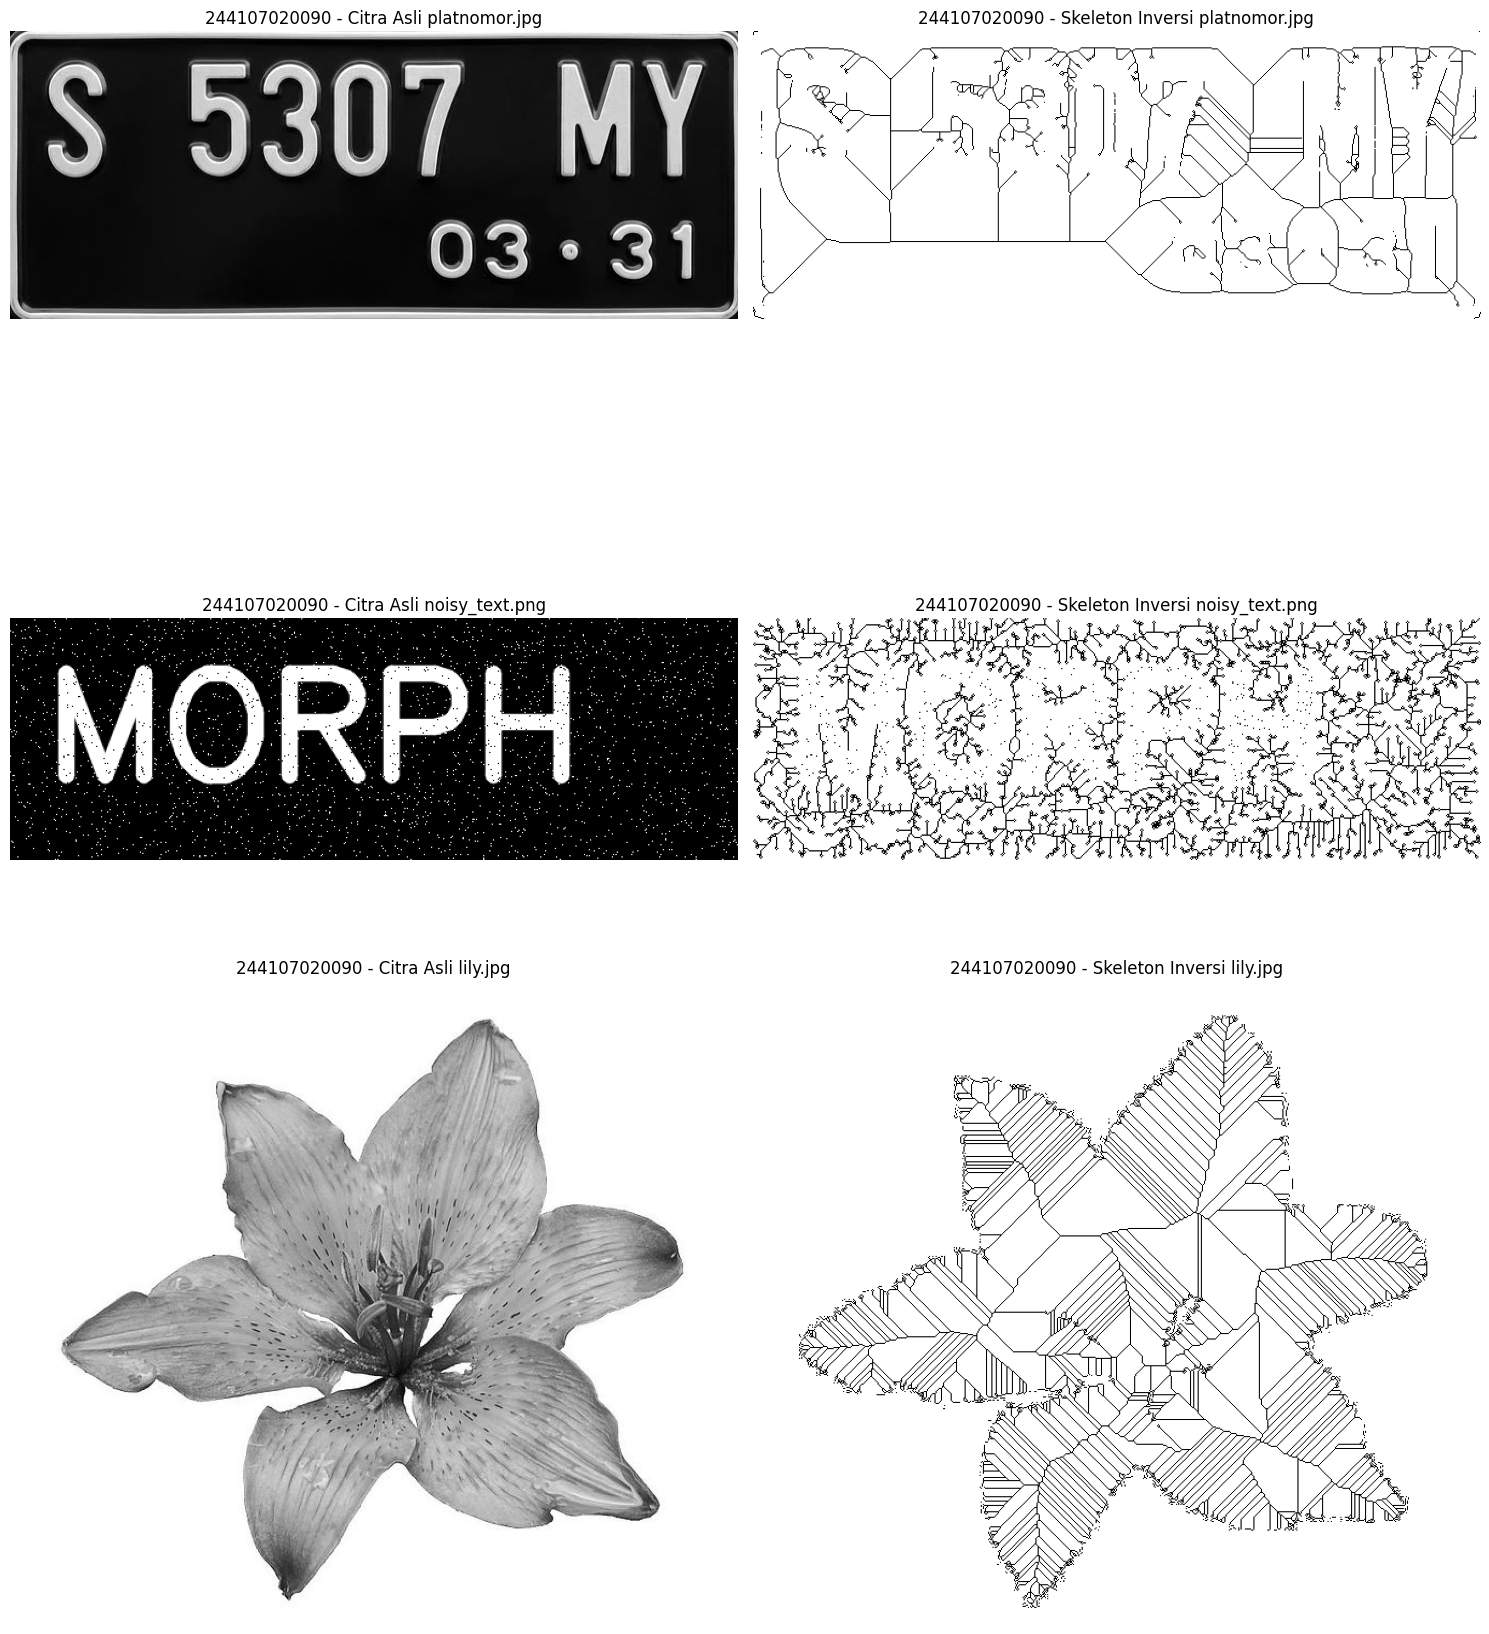

In [ ]:
# Mengimpor Library Ekstra Yang Dibutuhkan
from skimage import filters
from skimage.morphology import skeletonize

# Membaca Citra Plat Nomor, Noisy Text, Dan Bunga Lily Dalam Grayscale
img_plat = cv2.imread(BASE_PATH + 'platnomor.jpg', 0)
img_noisy = cv2.imread(BASE_PATH + 'noisy_text.png', 0)
img_lily = cv2.imread(BASE_PATH + 'lily.jpg', 0)

# Membuat Citra Biner Inversi Menggunakan Operator Kurang Dari (<)
# Area Gelap (Hitam) Akan Menjadi True, Area Terang Menjadi False
binary_inv_plat = img_plat < filters.threshold_triangle(img_plat)
binary_inv_noisy = img_noisy < filters.threshold_triangle(img_noisy)
binary_inv_lily = img_lily < filters.threshold_triangle(img_lily)

# Mengeksekusi Fungsi Skeletonize Pada Citra Biner Inversi
skeleton_inv_plat = skeletonize(binary_inv_plat)
skeleton_inv_noisy = skeletonize(binary_inv_noisy)
skeleton_inv_lily = skeletonize(binary_inv_lily)

# Menampilkan Citra Asli Dan Hasil Skeleton Inversi Secara Berdampingan
plt.figure(figsize=(15, 18))

# Menampilkan Hasil Untuk Plat Nomor
plt.subplot(321), plt.imshow(img_plat, cmap='gray')
plt.title('244107020090 - Citra Asli platnomor.jpg'), plt.axis('off')
plt.subplot(322), plt.imshow(skeleton_inv_plat, cmap='gray_r') # Menggunakan Colormap Reversed (gray_r)
plt.title('244107020090 - Skeleton Inversi platnomor.jpg'), plt.axis('off')

# Menampilkan Hasil Untuk Noisy Text
plt.subplot(323), plt.imshow(img_noisy, cmap='gray')
plt.title('244107020090 - Citra Asli noisy_text.png'), plt.axis('off')
plt.subplot(324), plt.imshow(skeleton_inv_noisy, cmap='gray_r') # Menggunakan Colormap Reversed (gray_r)
plt.title('244107020090 - Skeleton Inversi noisy_text.png'), plt.axis('off')

# Menampilkan Hasil Untuk Bunga Lily
plt.subplot(325), plt.imshow(img_lily, cmap='gray')
plt.title('244107020090 - Citra Asli lily.jpg'), plt.axis('off')
plt.subplot(326), plt.imshow(skeleton_inv_lily, cmap='gray_r') # Menggunakan Colormap Reversed (gray_r)
plt.title('244107020090 - Skeleton Inversi lily.jpg'), plt.axis('off')

plt.tight_layout()
plt.show()

17. Membuat Program Thinning Dengan Library

In [ ]:
from skimage import img_as_float
from skimage import morphology

# Membaca Citra Dalam Format Grayscale
img_plat = cv2.imread(BASE_PATH + 'platnomor.jpg', 0)
img_noisy = cv2.imread(BASE_PATH + 'noisy_text.png', 0)
img_lily = cv2.imread(BASE_PATH + 'lily.jpg', 0)

# Mengonversi Citra Menjadi Tipe Float Untuk Operasi Thresholding
img_float_plat = img_as_float(img_plat)
img_float_noisy = img_as_float(img_noisy)
img_float_lily = img_as_float(img_lily)

# Membuat Citra Biner Dengan Batas Threshold Kurang Dari 0.5
bin_plat = img_float_plat < 0.5
bin_noisy = img_float_noisy < 0.5
bin_lily = img_float_lily < 0.5

# Mengeksekusi Operasi Skeletonize Dan Thinning
skel_plat = morphology.skeletonize(bin_plat)
thin_plat = morphology.thin(bin_plat)

skel_noisy = morphology.skeletonize(bin_noisy)
thin_noisy = morphology.thin(bin_noisy)

skel_lily = morphology.skeletonize(bin_lily)
thin_lily = morphology.thin(bin_lily)

# Menampilkan Perbandingan Citra Input, Skeleton, Dan Thin
plt.figure(figsize=(15, 15))

# Menampilkan Hasil Plat Nomor
plt.subplot(331), plt.imshow(img_plat, cmap='gray')
plt.title('244107020090 - Input platnomor.jpg'), plt.axis('off')
plt.subplot(332), plt.imshow(skel_plat, cmap='gray')
plt.title('244107020090 - Skeleton platnomor.jpg'), plt.axis('off')
plt.subplot(333), plt.imshow(thin_plat, cmap='gray')
plt.title('244107020090 - Thin platnomor.jpg'), plt.axis('off')

# Menampilkan Hasil Noisy Text
plt.subplot(334), plt.imshow(img_noisy, cmap='gray')
plt.title('244107020090 - Input noisy_text.png'), plt.axis('off')
plt.subplot(335), plt.imshow(skel_noisy, cmap='gray')
plt.title('244107020090 - Skeleton noisy_text.png'), plt.axis('off')
plt.subplot(336), plt.imshow(thin_noisy, cmap='gray')
plt.title('244107020090 - Thin noisy_text.png'), plt.axis('off')

# Menampilkan Hasil Lily
plt.subplot(337), plt.imshow(img_lily, cmap='gray')
plt.title('244107020090 - Input lily.jpg'), plt.axis('off')
plt.subplot(338), plt.imshow(skel_lily, cmap='gray')
plt.title('244107020090 - Skeleton lily.jpg'), plt.axis('off')
plt.subplot(339), plt.imshow(thin_lily, cmap='gray')
plt.title('244107020090 - Thin lily.jpg'), plt.axis('off')

plt.tight_layout()
plt.show()